In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/base_fertilizante_crescimento.csv')

# Display the first 5 rows of the DataFrame
display(df.head())

,fertilizante_g,crescimento_cm
0,0,3
1,1,7
2,2,11
3,3,14
4,4,16


In [2]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = df[['fertilizante_g']]
y = df['crescimento_cm']

# Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")

Training set size: 8 samples
Testing set size: 3 samples


In [3]:
from sklearn.linear_model import LinearRegression

# Create a Linear Regression model
model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

# Display the model's coefficient and intercept
print(f"Coefficient: {model.coef_[0]:.2f}")
print(f"Intercept: {model.intercept_:.2f}")

Coefficient: -0.36
Intercept: 13.32


In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2): {r2:.2f}")

Mean Absolute Error (MAE): 6.30
Mean Squared Error (MSE): 48.69
R-squared (R2): -0.40


In [5]:
from sklearn.preprocessing import PolynomialFeatures

# Create polynomial features (degree 2 for a quadratic relationship)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

# Split the polynomial features into training and testing sets
X_train_poly, X_test_poly, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=42)

print("Polynomial features created successfully.")
print(f"Original features shape: {X.shape}")
print(f"Polynomial features shape: {X_poly.shape}")

Polynomial features created successfully.
Original features shape: (11, 1)
Polynomial features shape: (11, 2)


In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create a new Linear Regression model for polynomial features
poly_model = LinearRegression()

# Train the model using the polynomial training data
poly_model.fit(X_train_poly, y_train)

# Make predictions on the polynomial test set
y_pred_poly = poly_model.predict(X_test_poly)

# Calculate evaluation metrics for the polynomial model
mae_poly = mean_absolute_error(y_test, y_pred_poly)
mse_poly = mean_squared_error(y_test, y_pred_poly)
r2_poly = r2_score(y_test, y_pred_poly)

print(f"Polynomial Model - Coefficient (x): {poly_model.coef_[0]:.2f}")
print(f"Polynomial Model - Coefficient (x^2): {poly_model.coef_[1]:.2f}")
print(f"Polynomial Model - Intercept: {poly_model.intercept_:.2f}")
print(f"\nPolynomial Model - Mean Absolute Error (MAE): {mae_poly:.2f}")
print(f"Polynomial Model - Mean Squared Error (MSE): {mse_poly:.2f}")
print(f"Polynomial Model - R-squared (R2): {r2_poly:.2f}")

Polynomial Model - Coefficient (x): 5.63
Polynomial Model - Coefficient (x^2): -0.56
Polynomial Model - Intercept: 2.05

Polynomial Model - Mean Absolute Error (MAE): 0.77
Polynomial Model - Mean Squared Error (MSE): 0.62
Polynomial Model - R-squared (R2): 0.98


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


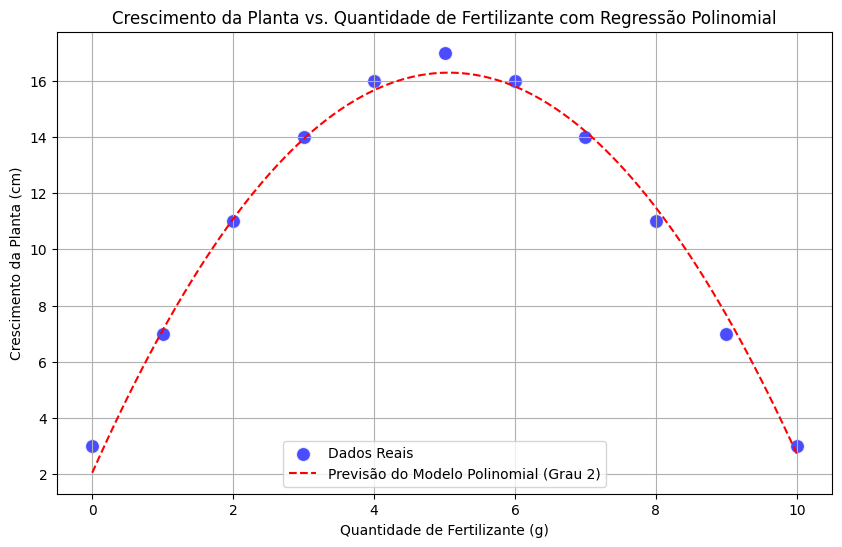

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Sort the original DataFrame by 'fertilizante_g' for a smooth curve plot
df_sorted = df.sort_values(by='fertilizante_g')

# Generate a range of 'fertilizante_g' values for plotting the curve
fertilizer_range = np.linspace(df_sorted['fertilizante_g'].min(), df_sorted['fertilizante_g'].max(), 100).reshape(-1, 1)

# Transform this range using the same PolynomialFeatures object used for training
fertilizer_range_poly = poly.transform(fertilizer_range)

# Predict 'crescimento_cm' for the generated range using the polynomial model
predicted_growth_curve = poly_model.predict(fertilizer_range_poly)

# Plotting
plt.figure(figsize=(10, 6))
sns.scatterplot(x='fertilizante_g', y='crescimento_cm', data=df_sorted, label='Dados Reais', s=100, color='blue', alpha=0.7)
sns.lineplot(x=fertilizer_range.flatten(), y=predicted_growth_curve, color='red', label='Previsão do Modelo Polinomial (Grau 2)', linestyle='--')

plt.title('Crescimento da Planta vs. Quantidade de Fertilizante com Regressão Polinomial')
plt.xlabel('Quantidade de Fertilizante (g)')
plt.ylabel('Crescimento da Planta (cm)')
plt.legend()
plt.grid(True)
plt.show()

## Análise dos Resultados do Modelo

### Regressão Linear Simples

O primeiro modelo de regressão linear simples tentou capturar a relação entre a quantidade de fertilizante (`fertilizante_g`) e o crescimento da planta (`crescimento_cm`). Os resultados foram os seguintes:

*   **Erro Médio Absoluto (MAE):** `6.30`
*   **Erro Quadrático Médio (MSE):** `48.69`
*   **R-squared (R2):** `-0.40`

O valor negativo do R-squared indica que o modelo linear não consegue explicar a variância nos dados e, na verdade, se ajusta pior do que simplesmente usar a média do crescimento da planta para todas as previsões. Isso sugeriu fortemente que a relação entre fertilizante e crescimento não é linear.

### Regressão Polinomial (Grau 2)

Reconhecendo a natureza não linear dos dados (onde o crescimento aumenta e depois diminui), um modelo de regressão polinomial de grau 2 foi implementado. Este modelo considera uma relação quadrática entre as variáveis. Os resultados obtidos foram:

*   **Coeficiente (x):** `5.63`
*   **Coeficiente (x^2):** `-0.56`
*   **Intercepto:** `2.05`
*   **Erro Médio Absoluto (MAE):** `0.77`
*   **Erro Quadrático Médio (MSE):** `0.62`
*   **R-squared (R2):** `0.98`

**Discussão:**

A melhoria com o modelo polinomial é drástica e clara:

*   **MAE e MSE:** Houve uma redução significativa nos valores de MAE e MSE. Um MAE de `0.77` significa que, em média, as previsões do modelo polinomial desviam apenas `0.77 cm` do crescimento real da planta, o que é uma precisão muito alta.
*   **R-squared (R2):** O valor de R2 de `0.98` é excelente. Isso indica que o modelo polinomial explica aproximadamente 98% da variância no crescimento da planta, o que significa que ele se ajusta muito bem aos dados e é capaz de prever o crescimento com alta confiabilidade com base na quantidade de fertilizante.

**Conclusão:**

O modelo de regressão polinomial de grau 2 é altamente eficaz para estimar o crescimento da planta com base na quantidade de fertilizante utilizada, refletindo com precisão a relação de otimização onde um nível ideal de fertilizante maximiza o crescimento, e quantidades excessivas podem prejudicá-lo.

## Resumo de Bibliotecas e Funções Utilizadas

Este notebook utiliza diversas bibliotecas populares de Python para manipulação de dados, modelagem de machine learning e visualização.

### Passo a Passo Lógico:

1.  **Carregamento e Inspeção de Dados**
    *   **`pandas` (importado como `pd`)**
        *   `pd.read_csv()`: Para carregar o conjunto de dados `base_fertilizante_crescimento.csv` em um DataFrame.
        *   `df.head()`: Para exibir as primeiras linhas do DataFrame e inspecionar a estrutura dos dados.
        *   `df[['coluna']]`: Para selecionar colunas específicas do DataFrame como recursos (`X`).
        *   `df['coluna']`: Para selecionar a coluna alvo (`y`).
        *   `df.sort_values()`: Para ordenar o DataFrame para fins de plotagem.

2.  **Preparação de Dados**
    *   **`sklearn.model_selection`**
        *   `train_test_split()`: Para dividir os dados em conjuntos de treino e teste, garantindo que o modelo seja avaliado em dados não vistos.

3.  **Modelagem: Regressão Linear Simples**
    *   **`sklearn.linear_model`**
        *   `LinearRegression()`: Para criar uma instância do modelo de regressão linear.
        *   `model.fit()`: Para treinar o modelo com os dados de treino (`X_train`, `y_train`).
        *   `model.coef_`: Para acessar o coeficiente angular do modelo.
        *   `model.intercept_`: Para acessar o intercepto do modelo.
        *   `model.predict()`: Para fazer previsões nos dados de teste (`X_test`).

4.  **Avaliação do Modelo: Regressão Linear Simples**
    *   **`sklearn.metrics`**
        *   `mean_absolute_error()`: Para calcular o erro médio absoluto (MAE).
        *   `mean_squared_error()`: Para calcular o erro quadrático médio (MSE).
        *   `r2_score()`: Para calcular o coeficiente de determinação R-squared (R2).

5.  **Preparação para Regressão Polinomial**
    *   **`sklearn.preprocessing`**
        *   `PolynomialFeatures()`: Para transformar os recursos originais em características polinomiais (neste caso, de grau 2).
        *   `poly.fit_transform()`: Para ajustar o transformador aos dados e aplicar a transformação.

6.  **Modelagem e Avaliação: Regressão Polinomial**
    *   **`sklearn.linear_model`**
        *   `LinearRegression()`: Reutilizado para criar e treinar um novo modelo com as características polinomiais (`X_train_poly`, `y_train`).
        *   `poly_model.fit()`: Treina o modelo polinomial.
        *   `poly_model.predict()`: Faz previsões com o modelo polinomial (`X_test_poly`).
    *   **`sklearn.metrics`**
        *   `mean_absolute_error()`, `mean_squared_error()`, `r2_score()`: Reutilizadas para avaliar o modelo polinomial.

7.  **Visualização dos Resultados**
    *   **`matplotlib.pyplot` (importado como `plt`)**
        *   `plt.figure()`: Para criar uma nova figura de plotagem.
        *   `plt.title()`: Para definir o título do gráfico.
        *   `plt.xlabel()`, `plt.ylabel()`: Para definir os rótulos dos eixos x e y.
        *   `plt.legend()`: Para exibir a legenda do gráfico.
        *   `plt.grid()`: Para adicionar uma grade ao gráfico.
        *   `plt.show()`: Para exibir o gráfico.
    *   **`numpy` (importado como `np`)**
        *   `np.linspace()`: Para gerar uma sequência de números uniformemente espaçados para criar uma curva suave.
        *   `reshape()`: Para redimensionar arrays NumPy.
    *   **`seaborn` (importado como `sns`)**
        *   `sns.scatterplot()`: Para plotar os pontos de dados reais (fertilizante vs. crescimento).
        *   `sns.lineplot()`: Para plotar a curva de previsão gerada pelo modelo polinomial.